In [1]:
from pathlib import Path
import sys
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, Image, display
from matplotlib.animation import FuncAnimation
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'configs' / 'training' / 'reflow_config.yaml').is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from data import Mano3DPlot, get_handx_loaders
from models import MotionDiT, TemporalUnet1D
from utils.reflow_parser import load_reflow_config
from utils.reflow_sampler import ReFlowSampler

CONFIG_PATH = PROJECT_ROOT / 'configs' / 'training' / 'reflow_config.yaml'
config = load_reflow_config(CONFIG_PATH)
MODEL_CLASSES = {
    'mdit': MotionDiT,
    'temporal_unet_1d': TemporalUnet1D,
}

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'device={device}')

device=cuda


In [2]:
checkpoint_path = Path(config['checkpoint_path'])
if not checkpoint_path.is_absolute():
    checkpoint_path = PROJECT_ROOT / checkpoint_path
if not checkpoint_path.is_file():
    raise FileNotFoundError(checkpoint_path)

checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
checkpoint_config = checkpoint.get('config', config)
if 'model_config' in checkpoint_config:
    model_name = Path(checkpoint_config['model_config']).stem
elif 'motion_dim' in checkpoint_config.get('model', {}):
    model_name = 'mdit'
else:
    model_name = 'temporal_unet_1d'
model = MODEL_CLASSES[model_name](**checkpoint_config['model']).to(device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

data_config = dict(checkpoint_config['data'])
data_root = Path(data_config['root'])
data_config['root'] = data_root if data_root.is_absolute() else PROJECT_ROOT / data_root
data_config.update(
    batch_size=1,
    num_workers=0,
    use_paraphrases=False,
    drop_last_train=False,
    target_length=model.time_length,
)
loaders = get_handx_loaders(**data_config)
sample_index = int(config['generation'].get('sample_index', 0))
sample = loaders['test'].dataset[sample_index]
sample_batch = loaders['test'].collate_fn([sample])
frame_mask = sample_batch['frame_mask'][0]
label = sample['text']

motion_mean = torch.as_tensor(
    checkpoint.get('motion_mean', loaders['train'].dataset.motion_mean),
    dtype=torch.float32,
).cpu()
motion_std = torch.as_tensor(
    checkpoint.get('motion_std', loaders['train'].dataset.motion_std),
    dtype=torch.float32,
).cpu()

print(f'checkpoint={checkpoint_path}')
print(f"id={sample['id']} source={sample['source']}")
print(f'label={label}')
print(
    f"real x={tuple(sample['x'].shape)} "
    f"model x={tuple(sample_batch['x'][0].shape)} "
    f"text_embedding={tuple(sample['text_embedding'].shape)}"
)

checkpoint=/home/infres/yrothlin-24/HandFlow/checkpoints/reflow/mdit.pt
id=test/00000000 source=HoloAssist
label=Left hand: The fingers perform minor bending motions, and then spread apart towards the end. The wrist moves to the right and slowly downwards. Right hand: The fingers gradually straighten while remaining close together. At the very end, the index fingertip makes contact with the thumb tip. Interaction: At the start, the left pinky tip briefly makes contact with the right pinky and ring fingertips. The hands then move apart.
real x=(60, 198) model x=(60, 198) text_embedding=(64, 512)


In [3]:
generation_config = config['generation']
sampler = ReFlowSampler(
    model,
    num_steps=int(generation_config['num_steps']),
    guidance_scale=1.5,
    seed=int(config.get('seed', 42)),
    device=device,
)
prediction_normalized = sampler.sample(
    text_embedding=sample['text_embedding'],
    attention_mask=sample['attention_mask'],
    frame_mask=frame_mask,
)
ground_truth_normalized = sample_batch['x'][0].cpu()
valid_length = int(sample['length'])

if bool(sample['motion_normalized']):
    ground_truth = ground_truth_normalized * motion_std + motion_mean
    prediction = prediction_normalized * motion_std + motion_mean
else:
    ground_truth = ground_truth_normalized
    prediction = prediction_normalized

ground_truth = ground_truth[:valid_length]
prediction = prediction[:valid_length]
assert ground_truth.shape == prediction.shape == (valid_length, model.in_channels)
print(f'ground_truth={tuple(ground_truth.shape)} prediction={tuple(prediction.shape)}')

ReFlow generation:   0%|          | 0/50 [00:00<?, ?it/s]

ground_truth=(60, 198) prediction=(60, 198)


In [4]:
visualizer = Mano3DPlot(device=str(device), fps=10)
ground_truth_mesh = visualizer.decode_features(
    ground_truth,
    sample['left_shape'],
    sample['right_shape'],
)
prediction_mesh = visualizer.decode_features(
    prediction,
    sample['left_shape'],
    sample['right_shape'],
)

left_error = np.linalg.norm(
    prediction_mesh['left_vertices'] - ground_truth_mesh['left_vertices'],
    axis=-1,
)
right_error = np.linalg.norm(
    prediction_mesh['right_vertices'] - ground_truth_mesh['right_vertices'],
    axis=-1,
)
vertex_error = np.concatenate((left_error, right_error), axis=1)
print(f'mean vertex error={vertex_error.mean():.6f}')

mean vertex error=0.146220


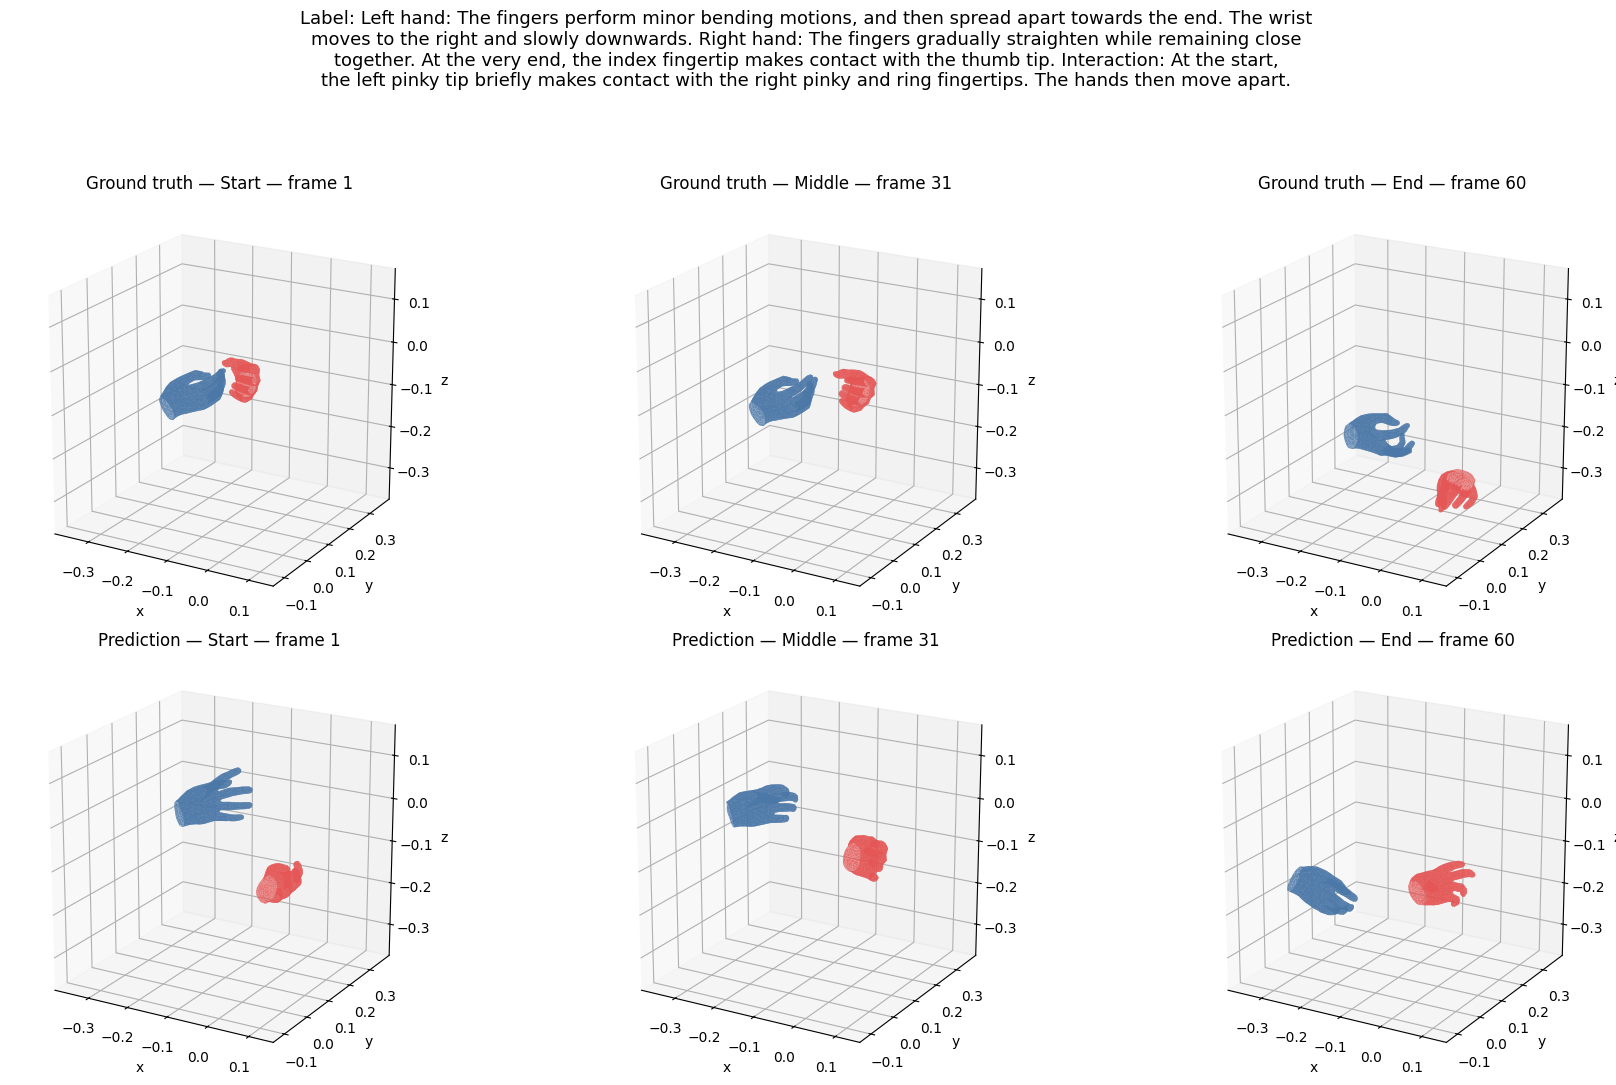

In [5]:
frame_count = len(ground_truth)
frame_ids = [0, frame_count // 2, frame_count - 1]
frame_names = ['Start', 'Middle', 'End']
comparisons = [
    ('Ground truth', ground_truth_mesh),
    ('Prediction', prediction_mesh),
]
all_vertices = np.concatenate([
    mesh[field].reshape(-1, 3)
    for _, mesh in comparisons
    for field in ('left_vertices', 'right_vertices')
])
minimum = all_vertices.min(axis=0)
maximum = all_vertices.max(axis=0)
center = (minimum + maximum) / 2
radius = max((maximum - minimum).max() / 2, 1e-3)

figure, axes = plt.subplots(
    2,
    3,
    figsize=(18, 11),
    subplot_kw={'projection': '3d'},
)
for row, (name, mesh) in enumerate(comparisons):
    for column, (frame_id, frame_name) in enumerate(zip(frame_ids, frame_names)):
        axis = axes[row, column]
        for vertices, faces, color in (
            (mesh['left_vertices'], mesh['left_faces'], visualizer.left_color),
            (mesh['right_vertices'], mesh['right_faces'], visualizer.right_color),
        ):
            axis.add_collection3d(Poly3DCollection(
                vertices[frame_id][faces],
                facecolor=color,
                edgecolor='none',
                alpha=0.85,
            ))
        axis.set_xlim(center[0] - radius, center[0] + radius)
        axis.set_ylim(center[1] - radius, center[1] + radius)
        axis.set_zlim(center[2] - radius, center[2] + radius)
        axis.set_box_aspect((1, 1, 1))
        axis.view_init(elev=20, azim=-60)
        axis.set_title(f'{name} — {frame_name} — frame {frame_id + 1}')
        axis.set_xlabel('x')
        axis.set_ylabel('y')
        axis.set_zlabel('z')

figure.suptitle(textwrap.fill(f'Label: {label}', 110), fontsize=13)
figure.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

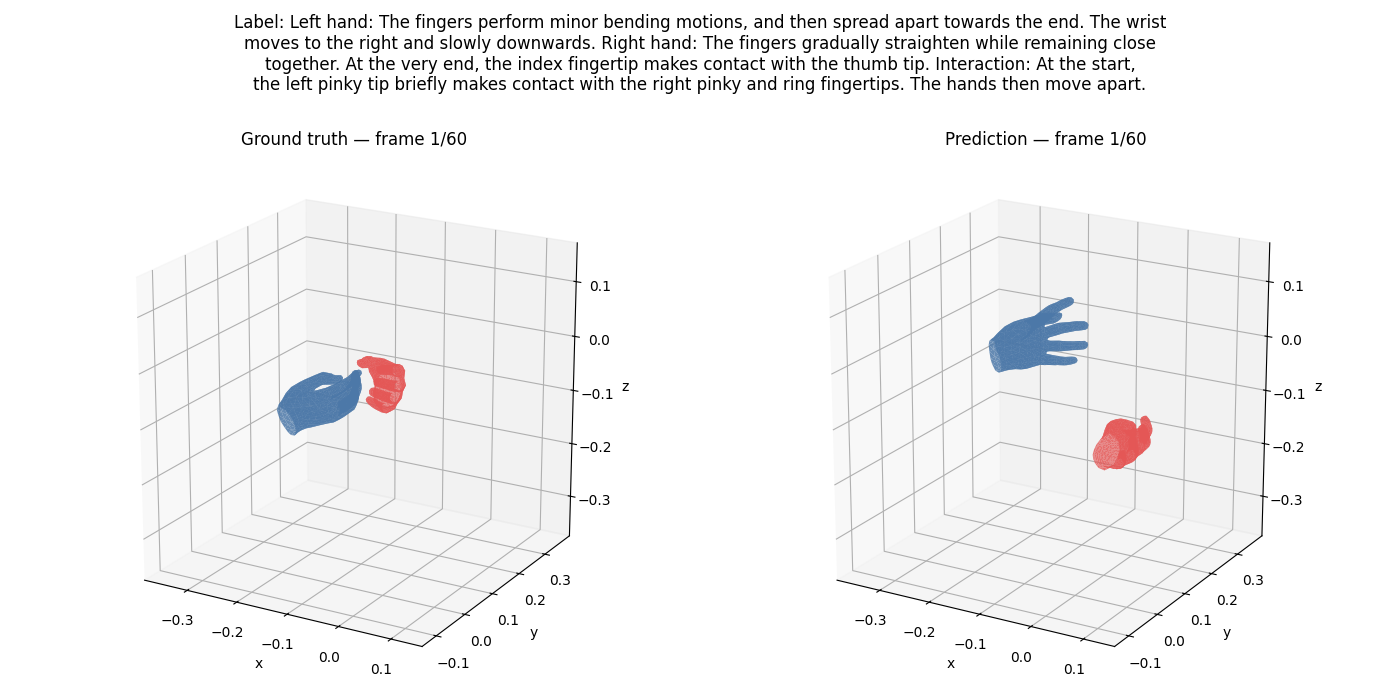

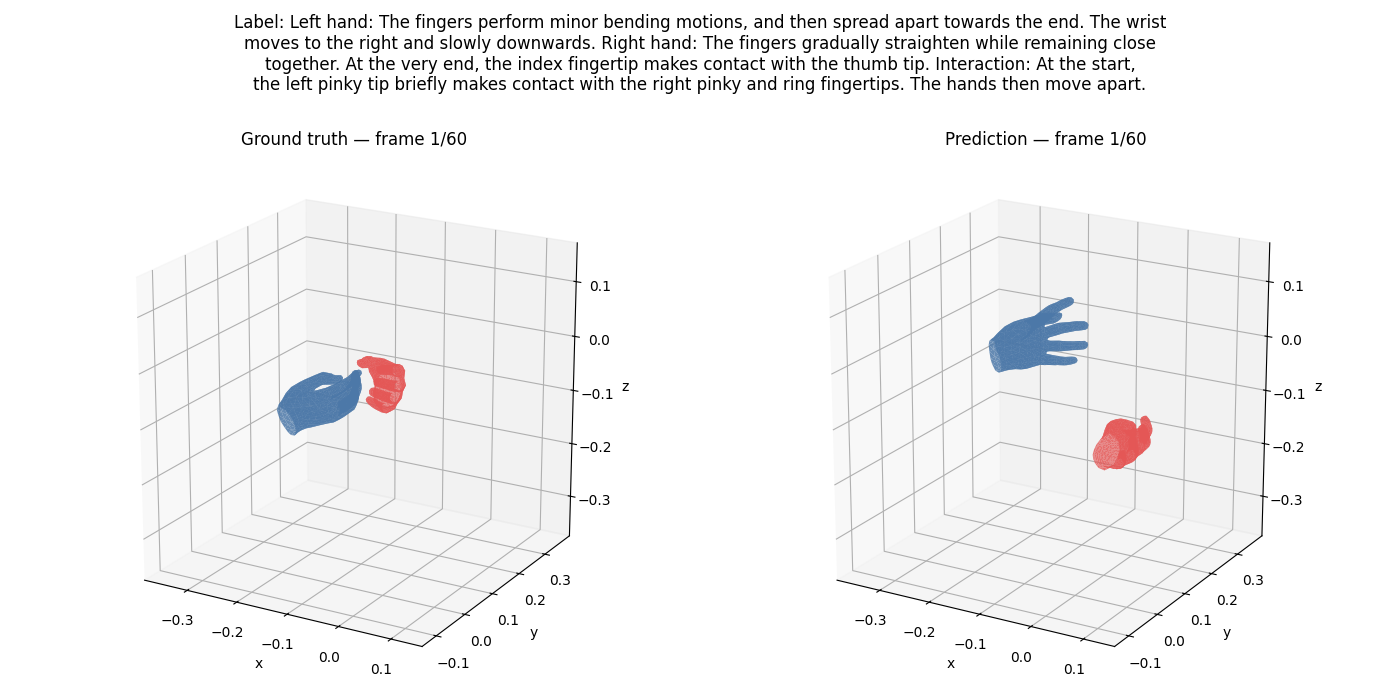

In [6]:
try:
    import ipympl
    get_ipython().run_line_magic('matplotlib', 'widget')
    widget_backend = True
except ImportError:
    widget_backend = False

animation = visualizer.animate_feature_comparison(
    ground_truth=ground_truth,
    prediction=prediction,
    left_betas=sample['left_shape'],
    right_betas=sample['right_shape'],
    title=textwrap.fill(f'Label: {label}', 110),
    max_frames=None,
    repeat=True,
)
if widget_backend:
    display(animation._fig.canvas)
else:
    display(HTML(animation.to_jshtml(fps=visualizer.fps, default_mode='loop')))
    plt.close(animation._fig)

In [7]:
gif_animation = visualizer.animate_feature_comparison(
    ground_truth=ground_truth,
    prediction=prediction,
    left_betas=sample['left_shape'],
    right_betas=sample['right_shape'],
    title=textwrap.fill(f'Label: {label}', 110),
    max_frames=None,
    repeat=True,
)
gif_path = (
    PROJECT_ROOT
    / 'materials'
    / 'gif'
    / f"{sample['id'].replace('/', '_')}_gt_vs_prediction.gif"
)
saved_gif = visualizer.save_gif(gif_animation, gif_path, dpi=100)
plt.close(gif_animation._fig)
print(f'GIF saved to {saved_gif}')

GIF saved to /home/infres/yrothlin-24/HandFlow/materials/gif/test_00000000_gt_vs_prediction.gif


ReFlow generation:   0%|          | 0/50 [00:00<?, ?it/s]

ReFlow generation:   0%|          | 0/50 [00:00<?, ?it/s]

ReFlow generation:   0%|          | 0/50 [00:00<?, ?it/s]

GIF saved to /home/infres/yrothlin-24/HandFlow/materials/gif/test_00000000_guidance_1_2_5.gif


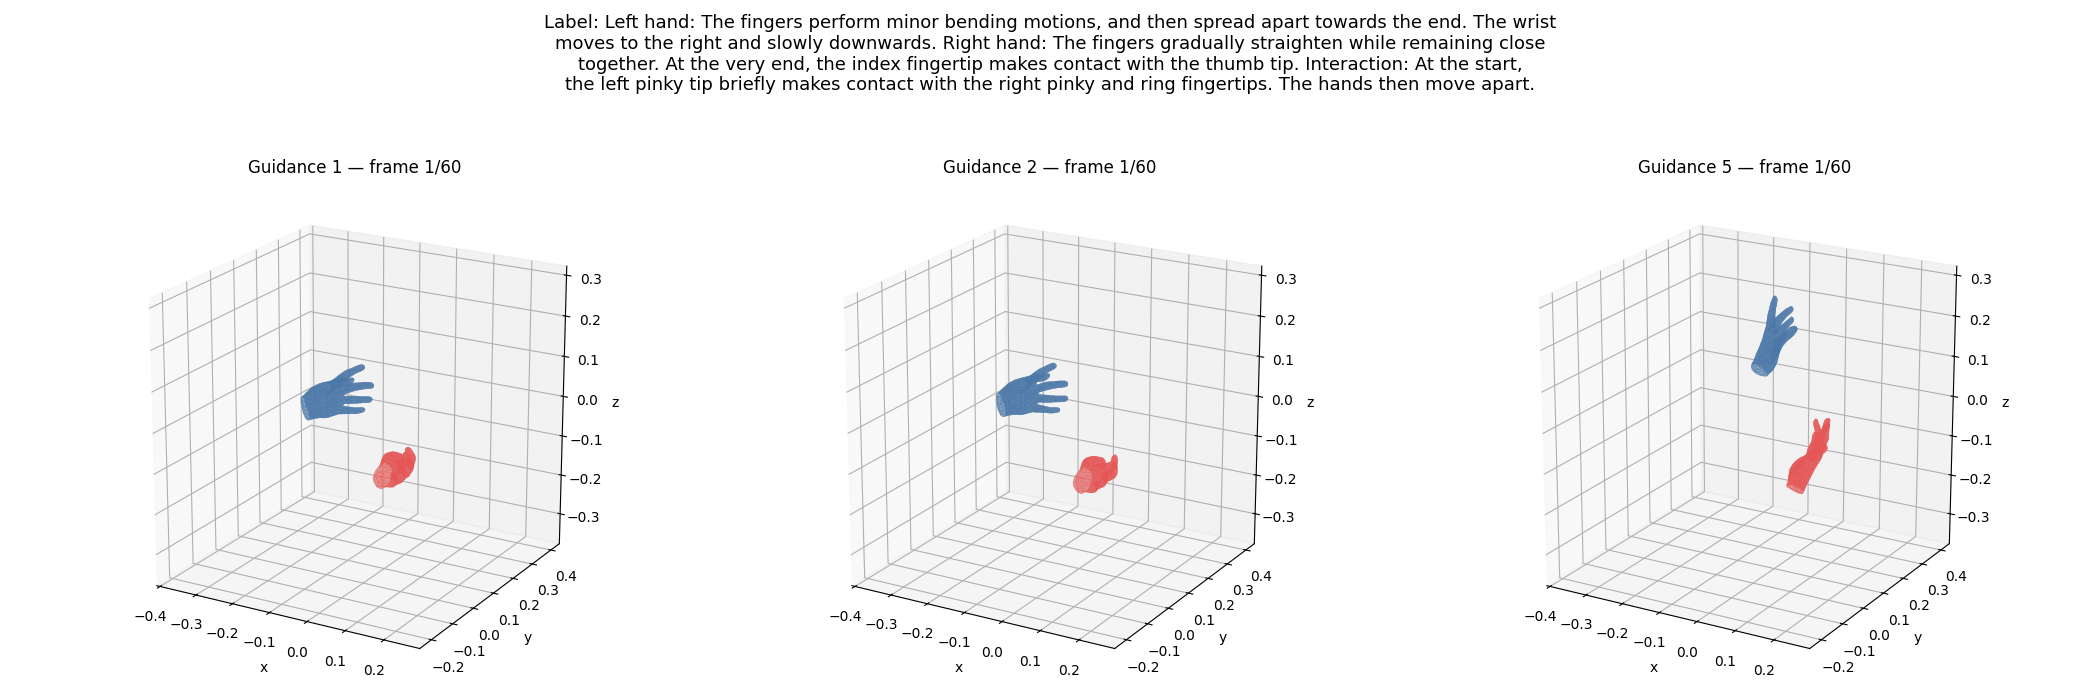

In [8]:
guidance_values = (1.0, 2.0, 5.0)
guidance_meshes = []
for guidance_value in guidance_values:
    guided_normalized = sampler.sample(
        text_embedding=sample['text_embedding'],
        attention_mask=sample['attention_mask'],
        frame_mask=frame_mask,
        guidance_scale=guidance_value,
    )
    if bool(sample['motion_normalized']):
        guided_prediction = guided_normalized * motion_std + motion_mean
    else:
        guided_prediction = guided_normalized
    guided_prediction = guided_prediction[:valid_length]
    guidance_meshes.append((
        guidance_value,
        visualizer.decode_features(
            guided_prediction,
            sample['left_shape'],
            sample['right_shape'],
        ),
    ))

guidance_points = np.concatenate([
    mesh[field].reshape(-1, 3)
    for _, mesh in guidance_meshes
    for field in ('left_vertices', 'right_vertices')
])
guidance_minimum = guidance_points.min(axis=0)
guidance_maximum = guidance_points.max(axis=0)
guidance_center = (guidance_minimum + guidance_maximum) / 2
guidance_radius = max(
    (guidance_maximum - guidance_minimum).max() / 2,
    1e-3,
)
guidance_figure, guidance_axes = plt.subplots(
    1,
    3,
    figsize=(21, 7),
    subplot_kw={'projection': '3d'},
)
guidance_artists = []
for axis, (guidance_value, mesh) in zip(guidance_axes, guidance_meshes):
    collections = []
    for vertices, faces, color in (
        (mesh['left_vertices'], mesh['left_faces'], visualizer.left_color),
        (mesh['right_vertices'], mesh['right_faces'], visualizer.right_color),
    ):
        collection = Poly3DCollection(
            vertices[0][faces],
            facecolor=color,
            edgecolor='none',
            alpha=0.85,
        )
        axis.add_collection3d(collection)
        collections.append((collection, vertices, faces))
    axis.set_xlim(guidance_center[0] - guidance_radius, guidance_center[0] + guidance_radius)
    axis.set_ylim(guidance_center[1] - guidance_radius, guidance_center[1] + guidance_radius)
    axis.set_zlim(guidance_center[2] - guidance_radius, guidance_center[2] + guidance_radius)
    axis.set_box_aspect((1, 1, 1))
    axis.view_init(elev=20, azim=-60)
    axis.set_xlabel('x')
    axis.set_ylabel('y')
    axis.set_zlabel('z')
    guidance_artists.append((axis, guidance_value, collections))

def update_guidance_comparison(frame_id):
    updated = []
    for axis, guidance_value, collections in guidance_artists:
        axis.set_title(
            f'Guidance {guidance_value:g} — frame {frame_id + 1}/{valid_length}'
        )
        for collection, vertices, faces in collections:
            collection.set_verts(vertices[frame_id][faces])
            updated.append(collection)
    return updated

guidance_figure.suptitle(textwrap.fill(f'Label: {label}', 110), fontsize=13)
guidance_figure.tight_layout(rect=(0, 0, 1, 0.9))
update_guidance_comparison(0)
guidance_animation = FuncAnimation(
    guidance_figure,
    update_guidance_comparison,
    frames=valid_length,
    interval=1000 / visualizer.fps,
    blit=False,
    repeat=True,
)
guidance_gif_path = (
    PROJECT_ROOT
    / 'materials'
    / 'gif'
    / f"{sample['id'].replace('/', '_')}_guidance_1_2_5.gif"
)
saved_guidance_gif = visualizer.save_gif(
    guidance_animation,
    guidance_gif_path,
    dpi=100,
)
plt.close(guidance_animation._fig)
print(f'GIF saved to {saved_guidance_gif}')
display(Image(filename=str(saved_guidance_gif)))